In [1]:
%%time
import os
import sys

import numpy as np
import seaborn as sns
import pandas as pd

from matplotlib import pyplot as plt

CPU times: total: 7.31 s
Wall time: 9.07 s


In [2]:
%%time
import sys

sys.path.append("../utils")

import data_io

CPU times: total: 93.8 ms
Wall time: 118 ms


# setup

In [3]:
%%time
cm = 1/2.54  # centimeters in inches
plt.style.use('paper.mplstyle')

CPU times: total: 15.6 ms
Wall time: 6.43 ms


In [4]:
%%time
order =[ 't1','GluMI','t2', 
        't3a', 't3b',  't4', 't5i', 't5o', 't5t', 'XBC',
        't6', 't7', 't8', 't9','RBC']

CPU times: total: 0 ns
Wall time: 15.5 μs


In [5]:
%%time
cell_type_colors = {'t1': '#da3b3c',
 'GluMI': '#1b75ab',
 't2': '#ffcad4',
 't3a': '#8d86b8',
 't3b': '#f0a54c',
 't4': '#6ca46c',
 't5o': '#0c7c5a',
 't5t': '#e0b0c8',
 't5i': '#487bb9',
 'XBC': '#e5603a',
 't7': '#ecc56f',
 't6': '#137983',
 't8': '#c195bc',
 't9': '#ef8538',
 'RBC': '#cacc7f'} 

CPU times: total: 0 ns
Wall time: 23.1 μs


In [6]:
%%time
GROUPS = {
    'OFF CBCs': ['t1', 'GluMI', 't2', 't3a', 't3b', 't4'],
    'ON CBCs':  ['t5i', 't5o', 't5t', 'XBC', 't6', 't7', 't8', 't9']
}

CPU times: total: 0 ns
Wall time: 18.8 μs


# load data

In [7]:
%%time
config = data_io.get_data_config()
version = config.get("version_ribbons", None)  # reads the dateframe of the latest ribbon df export
file_path = data_io.get_file_path(config,
                                  version = "version_ribbons",
                                  file_prefix = "file_prefix_ribbons")

CPU times: total: 15.6 ms
Wall time: 14.5 ms


In [8]:
%%time
assert os.path.isfile(file_path), file_path

CPU times: total: 0 ns
Wall time: 527 μs


In [9]:
%%time
RibbonCellFinal = pd.read_parquet(file_path)

CPU times: total: 5.59 s
Wall time: 1.88 s


In [10]:
%%time
RibbonCellFinal

CPU times: total: 0 ns
Wall time: 9.54 μs


,index,size,rb_centroid_x,rb_centroid_y,rb_centroid_z,rb_bbox_min_x,rb_bbox_min_y,rb_bbox_min_z,rb_bbox_max_x,rb_bbox_max_y,rb_bbox_max_z,size_nm3,rb_centroid_x_warped,rb_centroid_y_warped,rb_centroid_z_warped,supervoxel,cell,z_span,cell_type
0,0,351.0,53253.0,56169.0,487.0,53247.0,56162.0,486.0,53261.0,56178.0,490.0,3594240.0,853.051450,899.732403,-11.597616,79383433922874442,720575940558464428,4.0,RBC
2,2,448.0,40315.0,39964.0,721.0,40309.0,39957.0,720.0,40323.0,39971.0,725.0,4587520.0,646.852422,641.467405,-6.393510,77551716337734129,720575940550612539,5.0,RBC
3,3,362.0,63397.0,39940.0,1339.0,63391.0,39935.0,1337.0,63404.0,39948.0,1341.0,3706880.0,1014.628806,640.313069,11.614377,80718310026741444,720575940567764050,4.0,t2
4,4,593.0,13304.0,46209.0,753.0,13296.0,46200.0,752.0,13313.0,46217.0,757.0,6072320.0,217.584440,740.535835,-1.614160,73822997530114303,720575940563067632,5.0,t6
5,5,612.0,16412.0,51191.0,713.0,16404.0,51182.0,712.0,16421.0,51201.0,717.0,6266880.0,267.054322,819.125465,2.745772,74316197214624872,720575940552050815,5.0,t5o
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6671481,6671978,5348.0,13226.0,52518.0,1620.0,13163.0,52507.0,1596.0,13275.0,52528.0,1638.0,54763520.0,214.551695,840.434470,20.251927,73823822431946412,720575940576718340,42.0,t3b
6671483,6671980,5388.0,12978.0,46930.0,1476.0,12965.0,46903.0,1442.0,12988.0,46948.0,1507.0,55173120.0,211.923587,751.297359,21.970407,73823066450800346,720575940551035464,65.0,t3b
6671487,6671984,5486.0,62076.0,43906.0,1544.0,62043.0,43833.0,1529.0,62103.0,43943.0,1569.0,56176640.0,993.350201,703.677702,21.626389,80578053641651920,720575940550471551,40.0,t3b
6671488,6671985,5516.0,14105.0,48256.0,1102.0,14078.0,48216.0,1079.0,14143.0,48284.0,1127.0,56483840.0,230.116132,772.595180,11.964103,73964010030258543,720575940563090672,48.0,t3b


# figure

In [11]:
%%time
version_out = config.get("version", None)
fig_dir = f'../figures/connectivity/v{version_out}'   # saved the figure into the folder of the latest general version for completeness. 

os.makedirs(fig_dir, exist_ok=True)

CPU times: total: 0 ns
Wall time: 932 μs


## panel G: plot denisity across z

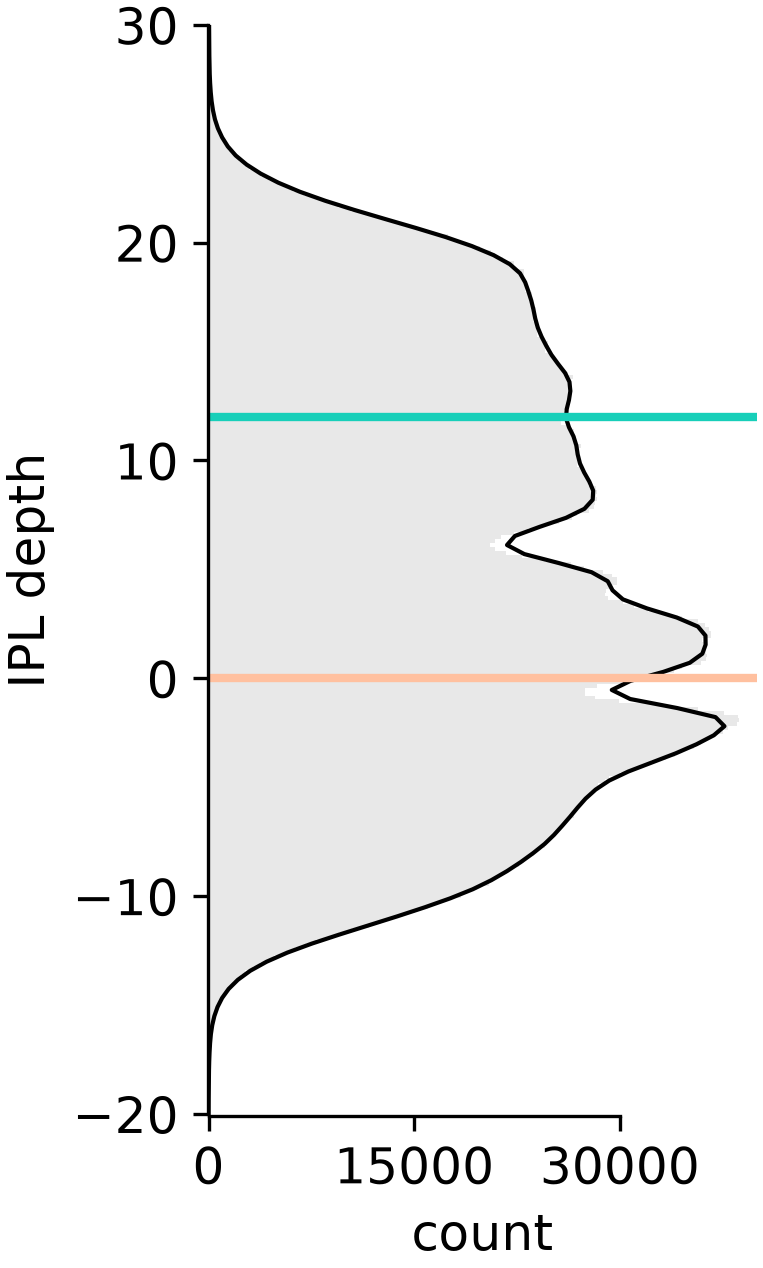

CPU times: total: 1min 4s
Wall time: 1min 7s


In [12]:
%%time
on_sac_pos = 0
off_sac_pos = 12

fig = plt.figure(figsize = (6*cm,12*cm))

gs = fig.add_gridspec(1,1, width_ratios=[1])

ax = fig.add_subplot(gs[0,0])
ax.set_ylim(-20.1,30)
ax.set_xlim(-50,40000)


hist = sns.histplot(RibbonCellFinal,  y = 'rb_centroid_z_warped', kde = True, 
                    common_norm = True, edgecolor = None,
                    color = 'lightgrey',  line_kws={'color': 'k'})

ax.lines[0].set_color('k')
plt.axhline(on_sac_pos, ls = "-",linewidth = 2, c= '#FFC09F')
plt.axhline(off_sac_pos, ls = "-",linewidth = 2, c= '#17CFB9')

plt.ylabel('IPL depth')
plt.xlabel('count')

# plt.ylabel(r'z [$\mu m$]')

ax.tick_params(direction='out')
ax.spines['left'].set_bounds(ax.get_yticks()[0], ax.get_yticks()[-1])
ax.spines['bottom'].set_bounds(ax.get_xticks()[0], ax.get_xticks()[-1])

# modify axis labels 
ax.set_yticks([-20,-10,0,10,20,30])
ax.set_xticks([0,15000,30000])


sns.despine(ax = ax, trim=True)


    
plt.show() 
ax.set_xlabel('count')


fig.savefig(f'{fig_dir}/fig8_G_density_z.svg')

In [13]:
from watermark import watermark
print(watermark())

Last updated: 2026-11-25T12:18:52.521371+01:00

Python implementation: CPython
Python version       : 3.13.5
IPython version      : 9.18.1

Compiler    : MSC v.1943 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 140 Stepping 1, GenuineIntel
CPU cores   : 8
Architecture: 64bit

